# MangoLeaf AI: seven-class threshold fitting v4

**Experimental candidate: `model-v4.0.0`. This notebook does not retrain or deploy the model.**

1. Load the completed v4 training folder and verify its files.
2. Choose margin and entropy using validation mango images and OOD tuning images only.
3. Save the settings before predicting test mango images and OOD report images.
4. Export the results and, if the retention target is met, a candidate model bundle.

OOD means images outside the seven supported classes. Confidence stays at 0.70.
The 95% retention target means accepted validation images, not 95% correct diagnoses.
These evaluation collections were previously used in development; they are not an independent field test.


## 1. Select the saved training run and OOD folder

**Purpose:** use the exact trained model and split without rebuilding them.
**Action:** set `TRAINING_RUN` to the folder printed by the training notebook, then check `OOD_DIR`.
**Expected result:** runtime versions and the threshold output folder are printed. You do not need the raw training folder here.

Generated outputs go to `MyDrive/mangoleaf_experiments/v4/threshold_fitting/v4-thresholds-<timestamp>-<id>/`.
An existing v4 training run in an older location still works: set `TRAINING_RUN` to its full path.

Keep the entire training run folder, including `dataset_split.zip`, model, manifests, and completion records.
OOD input may contain separate `tune/` and `report/` folders, or one flat collection split 50/50 with seed 42.
Extract OOD ZIPs first. Only exclude an image because its reviewed content is in scope, never because of its score.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import csv, hashlib, json, math, os, random, shutil, subprocess, sys, uuid, zipfile
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
import numpy as np
import tensorflow as tf
from PIL import Image

SEED = 42
CLASS_NAMES = ['anthracnose', 'bacterial_black_spot', 'bacterial_canker',
               'healthy_fruit', 'healthy_leaf', 'mango_scab', 'sooty_mold']
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
CONFIDENCE_THRESHOLD = 0.70
MIN_ID_RETENTION = 0.95  # Accepted mango images; not necessarily correct diagnoses.
MODEL_VERSION = 'model-v4.0.0'
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
PREPROCESSING = 'TensorFlow RGB decode; bilinear 224x224, no antialias; float32 0-255; model rescales internally'
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy('float32')
RUNTIME = {'python': sys.version, 'tensorflow': tf.__version__, 'keras': tf.keras.__version__,
           'numpy': np.__version__, 'pillow': Image.__version__}
print('Runtime:', RUNTIME)

# Paste the complete training run path printed by the training notebook.
EXPERIMENT_ROOT = Path('/content/drive/MyDrive/mangoleaf_experiments/v4')
TRAINING_RUN = EXPERIMENT_ROOT / 'training' / 'v4-training-20260923T111044Z-4b60a5aa'
OOD_DIR = Path('/content/drive/MyDrive/mango_ood_test')
OUTPUT_ROOT = EXPERIMENT_ROOT / 'threshold_fitting'
print('Threshold output root:', OUTPUT_ROOT)
OOD_EXCLUDE = []  # Exact paths relative to OOD_DIR, after reviewing image content.
GRID = [i / 100 for i in range(101)]
CONFIDENCE_ONLY = {'confidenceThreshold': 0.70, 'marginThreshold': 0.0, 'entropyThreshold': 1.0}


Mounted at /content/drive
Runtime: {'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]', 'tensorflow': '2.20.0', 'keras': '3.13.2', 'numpy': '2.1.3', 'pillow': '11.3.0'}
Threshold output root: /content/drive/MyDrive/mangoleaf_experiments/v4/threshold_fitting


In [2]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def object_hash(value):
    text = json.dumps(value, sort_keys=True, separators=(',', ':'), ensure_ascii=True)
    return hashlib.sha256(text.encode()).hexdigest()


def write_json_once(path, value):
    with Path(path).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, allow_nan=False)
        handle.write('\n')


def list_images(folder):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f'Image folder missing: {folder}')
    paths = sorted(p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    if not paths:
        raise ValueError(f'No supported images in {folder}')
    return paths


def verify_records_unchanged(rows):
    for row in rows:
        if sha256_file(row['path']) != row['sha256']:
            raise RuntimeError('Image changed: ' + row['path'])


def inside(root, relative):
    relative = PurePosixPath(relative)
    if relative.is_absolute() or '..' in relative.parts or '\\' in str(relative):
        raise ValueError('Unsafe relative path: ' + str(relative))
    target = (Path(root) / str(relative)).resolve()
    if not target.is_relative_to(Path(root).resolve()) or target == Path(root).resolve():
        raise ValueError('Path must stay inside its output folder.')
    return target


def extract_dataset(archive, rows, destination):
    # Extract only recorded images, then verify their contents before inference.
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=False)
    expected = {r['relativePath']: r for r in rows}
    if len(expected) != len(rows):
        raise ValueError('The image manifest repeats a destination path.')
    with zipfile.ZipFile(archive) as bundle:
        names = bundle.namelist()
        if len(names) != len(set(names)) or set(names) != set(expected):
            raise ValueError('Dataset ZIP entries differ from the image manifest.')
        for name, row in expected.items():
            target = inside(destination, name)
            if bundle.getinfo(name).file_size != row['bytes']:
                raise ValueError('Image size changed in dataset ZIP: ' + name)
            target.parent.mkdir(parents=True, exist_ok=True)
            with bundle.open(name) as source, target.open('xb') as output:
                shutil.copyfileobj(source, output)
            if sha256_file(target) != row['sha256']:
                raise ValueError('Image contents changed in dataset ZIP: ' + name)
    return [{**r, 'path': str(inside(destination, r['relativePath']))} for r in rows]


def verify_artifacts(folder, artifacts):
    for relative, expected in artifacts.items():
        path = inside(folder, relative)
        if not path.is_file() or sha256_file(path) != expected:
            raise RuntimeError('Missing or changed saved artifact: ' + relative)


def load_pixels(path):
    # This matches v3's Keras image loader. Do not divide by 255 again.
    pixels = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    pixels.set_shape((None, None, 3))
    return tf.image.resize(pixels, IMAGE_SIZE, method='bilinear',
                           preserve_aspect_ratio=False, antialias=False)


def predict_records(model, rows):
    output = []
    for start in range(0, len(rows), BATCH_SIZE):
        batch = rows[start:start + BATCH_SIZE]
        verify_records_unchanged(batch)
        pixels = tf.stack([load_pixels(r['path']) for r in batch])
        values = model(pixels, training=False).numpy()
        if values.shape != (len(batch), len(CLASS_NAMES)) or not np.isfinite(values).all():
            raise ValueError('The model must return seven finite probabilities per image.')
        output.extend(values.tolist())
    if not output:
        raise ValueError('Cannot predict an empty image collection.')
    return np.asarray(output, dtype=np.float32)


def weight_digest(model):
    digest = hashlib.sha256()
    for variable in model.weights:
        values = variable.numpy()
        digest.update(str(values.shape).encode())
        digest.update(str(values.dtype).encode())
        digest.update(values.tobytes())
    return digest.hexdigest()


def print_class_probabilities(probabilities, title):
    # Sort label-score pairs for display; keep the model's class order unchanged.
    ranked = sorted(zip(CLASS_NAMES, map(float, probabilities), strict=True),
                    key=lambda item: item[1], reverse=True)
    print('\n' + title)
    for label, probability in ranked:
        print(f"{label.replace('_', ' ').title():<24} {probability * 100:6.2f}%")


In [3]:
def verify_tfjs_export(folder):
    folder = Path(folder)
    graph = json.loads((folder / 'model.json').read_text(encoding='utf-8'))
    if graph.get('format') != 'graph-model':
        raise ValueError('Expected a TensorFlow.js Graph Model.')
    signature = graph.get('signature', {})
    outputs = list(signature.get('outputs', {}).values())
    inputs = list(signature.get('inputs', {}).values())
    dims = lambda tensor: [int(d['size']) for d in tensor['tensorShape']['dim']]
    if len(outputs) != 1 or dims(outputs[0])[-1:] != [len(CLASS_NAMES)]:
        raise ValueError('Export must expose seven output probabilities.')
    if len(inputs) != 1 or dims(inputs[0])[1:] != [224, 224, 3]:
        raise ValueError('Export input shape differs from the training plan.')
    dtypes = {'float32': '<f4', 'int32': '<i4', 'bool': '?'}
    used = set()
    for group in graph['weightsManifest']:
        parts = []
        for name in group['paths']:
            if name in used:
                raise ValueError('Repeated weight shard: ' + name)
            used.add(name)
            parts.append(inside(folder, name).read_bytes())
        buffer, offset = b''.join(parts), 0
        for weight in group['weights']:
            if 'quantization' in weight or weight['dtype'] not in dtypes:
                raise ValueError('This experiment requires unquantized float32 weights.')
            dtype = np.dtype(dtypes[weight['dtype']])
            count = math.prod(weight['shape'])
            size = count * dtype.itemsize
            if offset + size > len(buffer):
                raise ValueError('Truncated weight shard.')
            values = np.frombuffer(buffer[offset:offset + size], dtype=dtype)
            if not np.isfinite(values).all():
                raise ValueError('Non-finite values found in the exported weights.')
            offset += size
        if offset != len(buffer):
            raise ValueError('Weight manifest and shard sizes disagree.')
    if not used:
        raise ValueError('No exported weight shards.')
    return ['model.json'] + sorted(used)


In [4]:
def probability_stats(probabilities):
    stats = []
    for row in probabilities:
        values = [float(p) for p in row]
        if len(values) != len(CLASS_NAMES) or any(
                not math.isfinite(p) or p < 0 or p > 1 for p in values):
            raise ValueError('Expected seven finite probabilities in [0, 1].')
        if not math.isclose(sum(values), 1.0, abs_tol=1e-4):
            raise ValueError('Expected softmax probabilities summing to one.')
        ordered = sorted(values, reverse=True)
        stats.append({'confidence': ordered[0], 'margin': ordered[0] - ordered[1],
                      'entropy': -sum(p * math.log(p) for p in values if p > 0)
                                 / math.log(len(values)),
                      'predictedIndex': values.index(ordered[0]),
                      # Keep full precision in CSVs; only preview text is rounded.
                      **{f'probability_{label}': p for label, p in zip(CLASS_NAMES, values)}})
    return stats


def accepted(stat, thresholds):
    return (stat['confidence'] >= thresholds['confidenceThreshold']
            and stat['margin'] >= thresholds['marginThreshold']
            and stat['entropy'] <= thresholds['entropyThreshold'])


def select_thresholds(val_stats, ood_tune_stats, grid, confidence, min_retention):
    # Only tuning data enters this function. Counts avoid rounded-score ties.
    if not val_stats or not ood_tune_stats:
        raise ValueError('Both tuning subsets must contain predictions.')
    if not 0 < min_retention <= 1 or not 0 <= confidence <= 1:
        raise ValueError('Invalid confidence or retention target.')
    if not grid or any(not math.isfinite(x) or not 0 <= x <= 1 for x in grid):
        raise ValueError('Grid must contain finite values between zero and one.')
    required = math.ceil(min_retention * len(val_stats) - 1e-9)
    best, best_key, rows = None, None, []
    for margin in grid:
        val_eligible = [s for s in val_stats if s['confidence'] >= confidence and s['margin'] >= margin]
        ood_eligible = [s for s in ood_tune_stats if s['confidence'] >= confidence and s['margin'] >= margin]
        for entropy in grid:
            kept = sum(s['entropy'] <= entropy for s in val_eligible)
            rejected = len(ood_tune_stats) - sum(s['entropy'] <= entropy for s in ood_eligible)
            feasible = kept >= required
            rows.append({'margin': margin, 'entropy': entropy, 'valAccepted': kept,
                         'valTotal': len(val_stats), 'oodRejected': rejected,
                         'oodTotal': len(ood_tune_stats), 'meetsRetentionTarget': feasible})
            # Ties: more mango retention, then lower margin, then higher entropy.
            key = (rejected, kept, -margin, entropy)
            if feasible and (best_key is None or key > best_key):
                best_key = key
                best = {'confidenceThreshold': confidence, 'marginThreshold': margin,
                        'entropyThreshold': entropy}
    return best, rows


def scored_rows(records, stats, thresholds):
    if len(records) != len(stats):
        raise ValueError('Image and prediction counts differ.')
    rows = []
    for record, stat in zip(records, stats):
        keep = accepted(stat, thresholds)
        prediction = CLASS_NAMES[stat['predictedIndex']]
        reasons = []
        if stat['confidence'] < thresholds['confidenceThreshold']: reasons.append('confidence')
        if stat['margin'] < thresholds['marginThreshold']: reasons.append('margin')
        if stat['entropy'] > thresholds['entropyThreshold']: reasons.append('entropy')
        rows.append({**record, **stat, 'predictedClass': prediction, 'accepted': keep,
                     'returnedClass': prediction if keep else 'uncertain',
                     'rejectionReasons': ','.join(reasons),
                     'acceptedCorrect': keep and prediction == record['label']})
    return rows


def summarize(rows):
    if not rows:
        raise ValueError('Cannot report an empty subset.')
    count = len(rows)
    kept = sum(row['accepted'] for row in rows)
    report = {'total': count, 'accepted': kept, 'rejected': count - kept,
              'retention': kept / count, 'rejectionRate': (count - kept) / count}
    if all(row['label'] == 'OOD' for row in rows):
        report['falseAcceptRate'] = kept / count
        return report
    if any(row['label'] == 'OOD' for row in rows):
        raise ValueError('Report mango and OOD subsets separately.')
    correct = sum(row['acceptedCorrect'] for row in rows)
    report.update({'rawAccuracy': sum(row['predictedClass'] == row['label'] for row in rows) / count,
                   'acceptedCorrect': correct, 'acceptedWrong': kept - correct,
                   'acceptedAccuracy': correct / kept if kept else None,
                   'acceptedErrorsPerInput': (kept - correct) / count})
    per_class = {}
    confusion = [[0] * (len(CLASS_NAMES) + 1) for _ in CLASS_NAMES]
    for row in rows:
        column = row['predictedIndex'] if row['accepted'] else len(CLASS_NAMES)
        confusion[CLASS_NAMES.index(row['label'])][column] += 1
    for label in CLASS_NAMES:
        group = [row for row in rows if row['label'] == label]
        class_kept = sum(row['accepted'] for row in group)
        class_correct = sum(row['acceptedCorrect'] for row in group)
        per_class[label] = {'total': len(group), 'acceptedCorrect': class_correct,
                            'acceptedWrong': class_kept - class_correct,
                            'rejected': len(group) - class_kept,
                            'retention': class_kept / len(group) if group else None}
    healthy = {'healthy_leaf', 'healthy_fruit'}
    report['healthyErrorCounts'] = {
        'healthyAcceptedAsDisease': sum(r['accepted'] and r['label'] in healthy and r['predictedClass'] not in healthy for r in rows),
        'diseaseAcceptedAsHealthy': sum(r['accepted'] and r['label'] not in healthy and r['predictedClass'] in healthy for r in rows),
        'healthyOrganConfusion': sum(r['accepted'] and r['label'] in healthy and r['predictedClass'] in healthy and r['label'] != r['predictedClass'] for r in rows)}
    report['perClass'] = per_class
    report['confusion'] = {'rows': CLASS_NAMES, 'columns': CLASS_NAMES + ['uncertain'], 'counts': confusion}
    return report


def write_csv_once(path, rows):
    if not rows:
        raise ValueError('Cannot write an empty report.')
    with Path(path).open('x', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def read_frozen_selection(path, expected_sha256):
    if sha256_file(path) != expected_sha256:
        raise RuntimeError('Saved selection changed. Start a new run; do not retune during evaluation.')
    return json.loads(Path(path).read_text(encoding='utf-8'))


In [5]:
def prepare_ood(root, excluded):
    paths = list_images(root)
    available = {p.relative_to(root).as_posix(): p for p in paths}
    if len(excluded) != len(set(excluded)) or not set(excluded).issubset(available):
        raise ValueError('OOD_EXCLUDE repeats a path or names a missing image.')
    paths = [p for name, p in available.items() if name not in excluded]
    tune_dir, report_dir = root / 'tune', root / 'report'
    if tune_dir.is_dir() != report_dir.is_dir():
        raise ValueError('Provide both OOD tune/ and report/, or neither.')
    if tune_dir.is_dir():
        if any(p.relative_to(root).parts[0] not in ('tune', 'report') for p in paths):
            raise ValueError('OOD images outside tune/report would be ignored; fix the layout first.')
        groups = {'ood_tune': [p for p in paths if p.is_relative_to(tune_dir)],
                  'ood_report': [p for p in paths if p.is_relative_to(report_dir)]}
    else:
        if any(p.parent != root for p in paths):
            raise ValueError('Use a flat OOD folder or explicit tune/report folders.')
        paths = sorted(paths)
        order = np.random.RandomState(SEED).permutation(len(paths))
        half = len(paths) // 2
        groups = {'ood_tune': [paths[i] for i in sorted(order[:half])],
                  'ood_report': [paths[i] for i in sorted(order[half:])]}
    rows = []
    for subset, members in groups.items():
        if not members:
            raise ValueError('Each OOD subset needs at least one image.')
        for path in members:
            with Image.open(path) as picture:
                picture.convert('RGB').load()
            rows.append({'subset': subset, 'label': 'OOD', 'path': str(path),
                         'relativePath': path.relative_to(root).as_posix(),
                         'sha256': sha256_file(path), 'bytes': path.stat().st_size})
    return rows


def check_unique_contents(rows):
    seen = {}
    for row in rows:
        if row['sha256'] in seen:
            raise ValueError('Repeated image contents across the experiment: '
                             + seen[row['sha256']]['relativePath'] + ' and ' + row['relativePath'])
        seen[row['sha256']] = row


def frozen_training():
    if sha256_file(TRAINING_RUN / 'training_complete.json') != COMPLETE_SHA256:
        raise RuntimeError('The training completion record changed during this run.')
    verify_artifacts(TRAINING_RUN, complete['artifacts'])
    if weight_digest(model) != WEIGHTS_SHA256:
        raise RuntimeError('Model weights changed during inference.')


## 2. Verify the bundle and record evaluation inputs

**Purpose:** prevent mixed models, changed images, and repeated files from entering the report.
**Action:** run this cell. If a path or hash check fails, select the correct original file; do not disable the check.
**Expected result:** validation/test counts and OOD tuning/report counts are printed.
Reading file hashes and labels here does not make test predictions.


In [6]:
COMPLETE_PATH = TRAINING_RUN / 'training_complete.json'
if not COMPLETE_PATH.is_file():
    raise FileNotFoundError('Set TRAINING_RUN to the completed v4 run, including training_complete.json.')
complete = json.loads(COMPLETE_PATH.read_text(encoding='utf-8'))
COMPLETE_SHA256 = sha256_file(COMPLETE_PATH)
verify_artifacts(TRAINING_RUN, complete['artifacts'])
info = json.loads((TRAINING_RUN / 'resume_info.json').read_text(encoding='utf-8'))
manifest = json.loads((TRAINING_RUN / 'input_manifest.json').read_text(encoding='utf-8'))
if (complete['classes'] != CLASS_NAMES or info['classes'] != CLASS_NAMES or manifest['classes'] != CLASS_NAMES
        or complete['modelVersion'] != MODEL_VERSION or info['modelVersion'] != MODEL_VERSION
        or info['temperatureFoldedIntoWeights'] is not True or complete['testPredictionsRun'] is not False
        or info['preprocessing'] != PREPROCESSING or info['confidenceThreshold'] != CONFIDENCE_THRESHOLD
        or info['minimumValidationRetention'] != MIN_ID_RETENTION):
    raise ValueError('Training bundle or settings do not match the v4 experiment.')
MODEL_PATH = TRAINING_RUN / 'model_calibrated.keras'
if sha256_file(MODEL_PATH) != info['modelSha256']:
    raise ValueError('Saved model differs from the calibration record.')
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
if tuple(model.input_shape[1:]) != (224, 224, 3) or tuple(model.output_shape[1:]) != (7,):
    raise ValueError('Expected a 224x224 RGB input and seven output probabilities.')
WEIGHTS_SHA256 = weight_digest(model)
run_id = 'v4-thresholds-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:8]
RUN_DIR = OUTPUT_ROOT / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)
records = extract_dataset(TRAINING_RUN / 'dataset_split.zip', manifest['images'],
                          Path('/content/mangoleaf-threshold-v4') / run_id / 'dataset')
ood_records = prepare_ood(OOD_DIR, OOD_EXCLUDE)
check_unique_contents(records + ood_records)
val_records = [r for r in records if r['subset'] == 'val']
test_records = [r for r in records if r['subset'] == 'test']
tune_records = [r for r in ood_records if r['subset'] == 'ood_tune']
report_records = [r for r in ood_records if r['subset'] == 'ood_report']
for subset, group in [('val', val_records), ('test', test_records), ('ood_tune', tune_records), ('ood_report', report_records)]:
    if not group:
        raise ValueError('Empty subset: ' + subset)
    print(subset, len(group))
if min(len(tune_records), len(report_records)) < 20:
    print('Small OOD subsets: report counts and uncertainty; do not claim broad field reliability.')
INPUT_PATH = RUN_DIR / 'evaluation_inputs.json'
write_json_once(INPUT_PATH, {'trainingCompleteSha256': COMPLETE_SHA256, 'mango': manifest['images'],
                            'ood': ood_records, 'oodExcluded': OOD_EXCLUDE,
                            'evaluationStatus': info['evaluationStatus'], 'evaluationNotes': info['evaluationNotes']})
INPUT_SHA256 = sha256_file(INPUT_PATH)
print('Threshold run folder:', RUN_DIR)


val 391
test 393
ood_tune 83
ood_report 84
Threshold run folder: /content/drive/MyDrive/mangoleaf_experiments/v4/threshold_fitting/v4-thresholds-20260923T113957Z-90a3f917


## 3. Choose settings using validation and OOD tuning images

**Purpose:** reject unsupported inputs while meeting the stated validation-retention target.
**Action:** run once. Do not change the target after looking at test/report results.
**Expected result:** `selected_thresholds.json` records a feasible setting or an explicit `infeasible` result.

The search first maximizes OOD tuning rejection. Ties prefer more accepted validation images,
then a lower margin threshold and a higher entropy threshold. This matches the corrected v3.1 fitting method.
The original v3 test-based fitting method is not reused.


In [7]:
SELECTION_PATH = RUN_DIR / 'selected_thresholds.json'
if SELECTION_PATH.exists():
    raise RuntimeError('Settings already saved. Continue to evaluation without retuning.')
frozen_training()
val_probabilities = predict_records(model, val_records)
# A loader/backend mismatch must be investigated before changing thresholds.
reference = np.load(TRAINING_RUN / 'validation_probabilities.npy', allow_pickle=False)
np.testing.assert_allclose(val_probabilities, reference, rtol=1e-4, atol=1e-4,
                           err_msg='Validation predictions differ from the saved calibrated model run.')
val_stats = probability_stats(val_probabilities.tolist())
tune_stats = probability_stats(predict_records(model, tune_records).tolist())
chosen, grid_results = select_thresholds(val_stats, tune_stats, GRID, CONFIDENCE_THRESHOLD, MIN_ID_RETENTION)
selection = {'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES,
             'status': 'feasible' if chosen else 'infeasible', 'thresholds': chosen,
             'confidenceOnlyReference': CONFIDENCE_ONLY, 'minimumValidationRetention': MIN_ID_RETENTION,
             'grid': GRID, 'objective': 'maximum OOD tune rejection with the validation retention floor',
             'tieBreak': 'maximum validation retention, minimum margin, maximum entropy',
             'trainingCompleteSha256': COMPLETE_SHA256, 'evaluationInputsSha256': INPUT_SHA256,
             'modelSha256': info['modelSha256'], 'loadedWeightsSha256': WEIGHTS_SHA256,
             'runtime': RUNTIME, 'preprocessing': PREPROCESSING,
             'evaluationStatus': info['evaluationStatus'], 'evaluationNotes': info['evaluationNotes'],
             'confidenceOnlyValidation': summarize(scored_rows(val_records, val_stats, CONFIDENCE_ONLY)),
             'selectedAt': datetime.now(timezone.utc).isoformat()}
if chosen:
    selection['validation'] = summarize(scored_rows(val_records, val_stats, chosen))
    selection['oodTune'] = summarize(scored_rows(tune_records, tune_stats, chosen))
    write_csv_once(RUN_DIR / 'tuning_predictions.csv', scored_rows(val_records, val_stats, chosen)
                   + scored_rows(tune_records, tune_stats, chosen))
write_csv_once(RUN_DIR / 'threshold_search.csv', grid_results)
frozen_training()
write_json_once(SELECTION_PATH, selection)
SELECTION_SHA256 = sha256_file(SELECTION_PATH)
print('Saved status:', selection['status'], 'settings:', chosen)
print('Selection SHA-256:', SELECTION_SHA256)
if not chosen:
    print('No setting meets the target. Evaluation can report confidence-only behavior; no candidate model will be packaged.')


Saved status: feasible settings: {'confidenceThreshold': 0.7, 'marginThreshold': 0.0, 'entropyThreshold': 0.34}
Selection SHA-256: 4b96a4cfb96b733d37f38c114034428c164d26a7ce2779c143ecbedc27d28c35


## 4. Evaluate the saved settings

**Purpose:** measure behavior on test mango images and the separate OOD report collection.
**Action:** run once after the selection is saved. Do not use these results to retune the same report.
**Expected result:** raw seven-class metrics, accepted/rejected results, a confidence-only comparison,
confusion matrices, and separate healthy-leaf/healthy-fruit results.

A rejected mango image is counted separately from an accepted wrong diagnosis.
An accepted OOD image is a false acceptance. Small class counts make percentages uncertain.
The old six-class 97.46% figure and this seven-class accuracy measure different classification tasks.


In [8]:
if (RUN_DIR / 'evaluation_started.json').exists():
    raise RuntimeError('Evaluation already started. Preserve this run; do not retune or overwrite its results.')
saved = read_frozen_selection(SELECTION_PATH, SELECTION_SHA256)
if sha256_file(INPUT_PATH) != INPUT_SHA256 or saved['evaluationInputsSha256'] != INPUT_SHA256:
    raise RuntimeError('The saved evaluation inputs changed.')
frozen_training()
verify_records_unchanged(records + ood_records)
write_json_once(RUN_DIR / 'evaluation_started.json', {'selectionSha256': SELECTION_SHA256,
                                                    'startedAt': datetime.now(timezone.utc).isoformat()})
test_probabilities = predict_records(model, test_records)
report_probabilities = predict_records(model, report_records)
test_stats = probability_stats(test_probabilities.tolist())
report_stats = probability_stats(report_probabilities.tolist())
settings = {'confidence_only': saved['confidenceOnlyReference']}
if saved['status'] == 'feasible':
    settings['selected'] = saved['thresholds']
reports = {}
for name, thresholds in settings.items():
    mango_rows = scored_rows(test_records, test_stats, thresholds)
    ood_rows = scored_rows(report_records, report_stats, thresholds)
    reports[name] = {'mango': summarize(mango_rows), 'ood': summarize(ood_rows)}
    write_csv_once(RUN_DIR / f'{name}_test_predictions.csv', mango_rows)
    write_csv_once(RUN_DIR / f'{name}_ood_report_predictions.csv', ood_rows)
from sklearn.metrics import classification_report, confusion_matrix
y_true = np.asarray([CLASS_NAMES.index(r['label']) for r in test_records])
y_pred = test_probabilities.argmax(axis=1)
raw_report = classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
                                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)
raw_confusion = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
evaluation = {'status': saved['status'], 'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES,
              'selectionSha256': SELECTION_SHA256, 'evaluationInputsSha256': INPUT_SHA256,
              'trainingCompleteSha256': COMPLETE_SHA256, 'rawClassificationReport': raw_report,
              'rawConfusionMatrix': raw_confusion.tolist(), 'gatedReports': reports,
              'evaluationStatus': info['evaluationStatus'], 'evaluationNotes': info['evaluationNotes'],
              'runtime': RUNTIME, 'finishedAt': datetime.now(timezone.utc).isoformat()}
evaluation['calibratedTestCrossEntropy'] = float(-np.log(np.maximum(test_probabilities[np.arange(len(y_true)), y_true], 1e-7)).mean())
read_frozen_selection(SELECTION_PATH, SELECTION_SHA256)
frozen_training()
verify_records_unchanged(records + ood_records)
write_json_once(RUN_DIR / 'evaluation.json', evaluation)
EVALUATION_SHA256 = sha256_file(RUN_DIR / 'evaluation.json')
FIG_DIR = RUN_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=False)
write_json_once(RUN_DIR / 'run_record.json', {'training': info, 'selection': saved, 'evaluation': evaluation})
write_csv_once(FIG_DIR / 'per_class_metrics.csv', [
    {'class': label, **raw_report[label]} for label in CLASS_NAMES])
print(classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, zero_division=0))
for name, result in reports.items():
    print(name, 'mango:', result['mango']['rawAccuracy'], 'raw accuracy;',
          result['mango']['retention'], 'retention;', result['ood']['falseAcceptRate'], 'OOD false acceptance')


                      precision    recall  f1-score   support

         anthracnose       0.99      1.00      0.99        73
bacterial_black_spot       0.91      0.91      0.91        45
    bacterial_canker       1.00      1.00      1.00        74
       healthy_fruit       0.94      0.94      0.94        17
        healthy_leaf       1.00      1.00      1.00        75
          mango_scab       0.88      0.88      0.88        34
          sooty_mold       1.00      0.99      0.99        75

            accuracy                           0.97       393
           macro avg       0.96      0.96      0.96       393
        weighted avg       0.97      0.97      0.97       393

confidence_only mango: 0.9745547073791349 raw accuracy; 0.9592875318066157 retention; 0.38095238095238093 OOD false acceptance
selected mango: 0.9745547073791349 raw accuracy; 0.9541984732824428 retention; 0.2619047619047619 OOD false acceptance


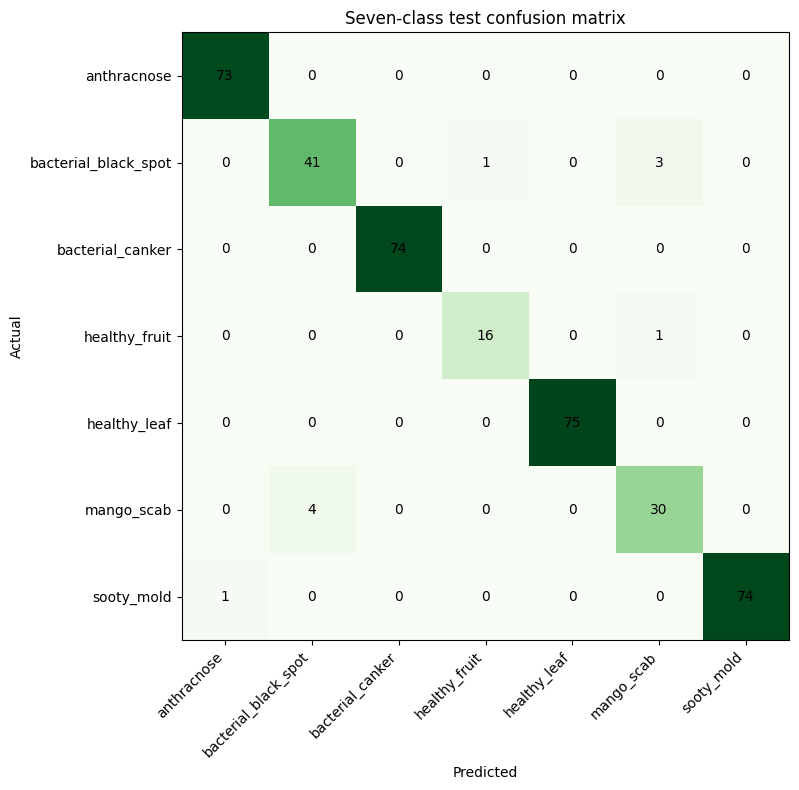

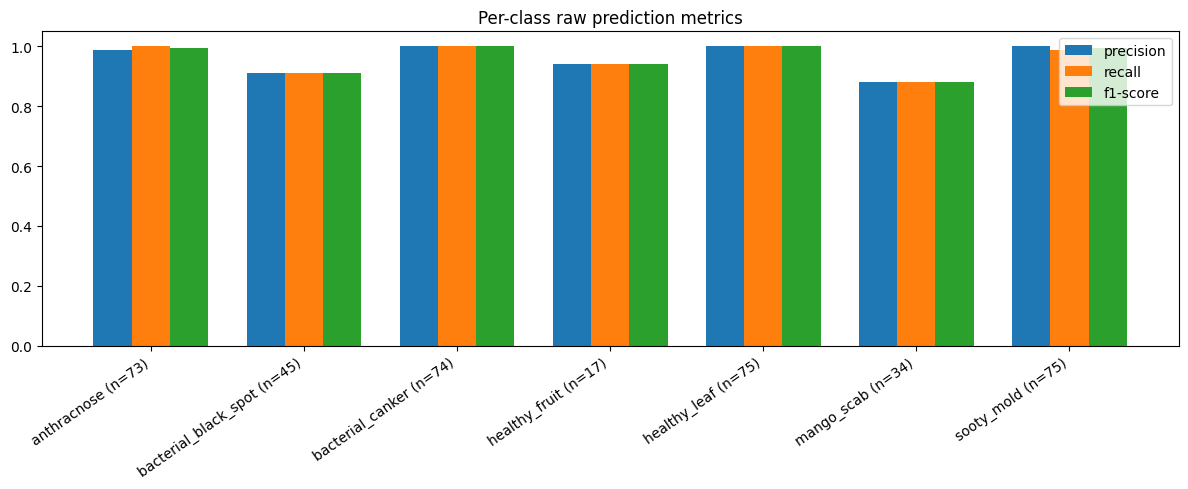

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(raw_confusion, cmap='Greens')
ax.set_xticks(range(7), CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(7), CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Seven-class test confusion matrix')
for i in range(7):
    for j in range(7):
        ax.text(j, i, str(raw_confusion[i, j]), ha='center', va='center')
fig.tight_layout(); fig.savefig(FIG_DIR / 'confusion_matrix.png', dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(CLASS_NAMES))
for offset, metric in [(-0.25, 'precision'), (0, 'recall'), (0.25, 'f1-score')]:
    ax.bar(x + offset, [raw_report[c][metric] for c in CLASS_NAMES], width=0.25, label=metric)
ax.set_xticks(x, [f"{c} (n={raw_report[c]['support']:.0f})" for c in CLASS_NAMES], rotation=35, ha='right')
ax.set_ylim(0, 1.05); ax.legend(); ax.set_title('Per-class raw prediction metrics')
fig.tight_layout(); fig.savefig(FIG_DIR / 'per_class_metrics.png', dpi=150); plt.show()


## Inspect one evaluated image's class probabilities

**Purpose:** see every class score for an image after Step 4 has finished.
**Action:** set `DEBUG_SUBSET` to `test` or `ood_report`, then choose `DEBUG_IMAGE_INDEX` (0 means the first image). Rerun only this cell to inspect another image.
**Expected result:** filename, actual label, acceptance decision, and all seven percentages from the already computed predictions. No new inference runs here.

These probabilities describe one image, not per-class accuracy. Rounded percentages may not total exactly 100%. OOD has no separate output class. A rejected image still receives scores across the known classes. Full-precision `probability_<class>` columns are saved in the prediction CSVs. Do not use test/report observations to retune this evaluation run.


In [16]:
DEBUG_SUBSET = 'test'  # Choose 'test' or 'ood_report'.
DEBUG_IMAGE_INDEX = 0  # Zero means the first already evaluated image.

preview_saved = read_frozen_selection(SELECTION_PATH, SELECTION_SHA256)
preview_sets = {'test': (test_records, test_probabilities, test_stats),
                'ood_report': (report_records, report_probabilities, report_stats)}
if DEBUG_SUBSET not in preview_sets:
    raise ValueError("DEBUG_SUBSET must be 'test' or 'ood_report'.")
preview_records, preview_probabilities, preview_stats = preview_sets[DEBUG_SUBSET]
if not isinstance(DEBUG_IMAGE_INDEX, int) or not 0 <= DEBUG_IMAGE_INDEX < len(preview_records):
    raise ValueError(f'Choose an image index from 0 to {len(preview_records) - 1}.')
preview_record = preview_records[DEBUG_IMAGE_INDEX]
preview_thresholds = (preview_saved['thresholds'] if preview_saved['status'] == 'feasible'
                      else preview_saved['confidenceOnlyReference'])
preview_accepted = accepted(preview_stats[DEBUG_IMAGE_INDEX], preview_thresholds)
print('Decision:', 'accepted' if preview_accepted else 'rejected',
      '| gates:', 'selected' if preview_saved['status'] == 'feasible' else 'confidence-only (fitting infeasible)')
print_class_probabilities(preview_probabilities[DEBUG_IMAGE_INDEX],
    f"{DEBUG_SUBSET}: {preview_record['relativePath']} | actual: {preview_record['label']}")


Decision: accepted | gates: selected

test: test/anthracnose/anthracnose__20211008_124301 (Custom).jpg | actual: anthracnose
Anthracnose               99.97%
Bacterial Canker           0.02%
Healthy Leaf               0.00%
Sooty Mold                 0.00%
Bacterial Black Spot       0.00%
Healthy Fruit              0.00%
Mango Scab                 0.00%


## 5. Package the candidate and evidence

**Purpose:** keep weights, class mapping, thresholds, and reports together.
**Action:** run this cell and retain the printed Drive folder. Download its ZIPs when needed.
**Expected result:** `v4-thresholds-<timestamp>-<id>-evidence.zip`, plus a matching `-candidate_model.zip` only when fitting was feasible.
The version and run ID remain visible when these ZIPs are downloaded outside their Drive folder.

A feasible setting is not automatic approval for deployment. Review mistakes, OOD acceptance,
healthy-class results, and later application compatibility before adopting this model.


In [17]:
read_frozen_selection(SELECTION_PATH, SELECTION_SHA256)
if sha256_file(RUN_DIR / 'evaluation.json') != EVALUATION_SHA256:
    raise RuntimeError('Evaluation changed before packaging.')
frozen_training()
# Include the run name so downloaded ZIPs identify their version and attempt.
EVIDENCE_ZIP = RUN_DIR / f'{RUN_DIR.name}-evidence.zip'
CANDIDATE_ZIP = RUN_DIR / f'{RUN_DIR.name}-candidate_model.zip'
if saved['status'] == 'feasible':
    source_dir = inside(TRAINING_RUN, complete['tfjsDirectory'])
    model_files = verify_tfjs_export(source_dir)
    candidate_dir = RUN_DIR / 'candidate_model'
    candidate_dir.mkdir(exist_ok=False)
    for name in model_files:
        destination = inside(candidate_dir, name)
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(inside(source_dir, name), destination)
    config = {'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES, 'inputSize': list(IMAGE_SIZE),
              'preprocessing': PREPROCESSING, 'temperature': info['temperature'],
              'temperatureFoldedIntoWeights': True, 'thresholds': saved['thresholds'],
              'status': 'experimental; not adopted or deployed', 'selectionSha256': SELECTION_SHA256,
              'evaluationSha256': EVALUATION_SHA256, 'trainingCompleteSha256': COMPLETE_SHA256}
    write_json_once(candidate_dir / 'model_config.json', config)
    with zipfile.ZipFile(CANDIDATE_ZIP, 'x', compression=zipfile.ZIP_DEFLATED) as bundle:
        for path in sorted(candidate_dir.rglob('*')):
            if path.is_file(): bundle.write(path, path.relative_to(candidate_dir).as_posix())
    write_json_once(RUN_DIR / 'candidate_hashes.json', {
        p.relative_to(candidate_dir).as_posix(): sha256_file(p) for p in sorted(candidate_dir.rglob('*')) if p.is_file()})
with zipfile.ZipFile(EVIDENCE_ZIP, 'x', compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(RUN_DIR.iterdir()):
        if path.is_file() and path.suffix != '.zip': bundle.write(path, path.name)
    for path in sorted(FIG_DIR.iterdir()):
        if path.is_file(): bundle.write(path, path.relative_to(RUN_DIR).as_posix())
    for name in ['resume_info.json', 'plan.json', 'duplicate_audit.json', 'reviewed_images.json', 'training_complete.json']:
        bundle.write(TRAINING_RUN / name, 'training/' + name)
print('EVIDENCE READY:', RUN_DIR)
print('Evidence ZIP:', EVIDENCE_ZIP)
if saved['status'] == 'feasible': print('Candidate ZIP:', CANDIDATE_ZIP)
else: print('No deployable candidate was packaged because the retention target was not met.')


EVIDENCE READY: /content/drive/MyDrive/mangoleaf_experiments/v4/threshold_fitting/v4-thresholds-20260923T113957Z-90a3f917
Evidence ZIP: /content/drive/MyDrive/mangoleaf_experiments/v4/threshold_fitting/v4-thresholds-20260923T113957Z-90a3f917/v4-thresholds-20260923T113957Z-90a3f917-evidence.zip
Candidate ZIP: /content/drive/MyDrive/mangoleaf_experiments/v4/threshold_fitting/v4-thresholds-20260923T113957Z-90a3f917/v4-thresholds-20260923T113957Z-90a3f917-candidate_model.zip


## References and record keeping

- [Keras transfer learning](https://keras.io/guides/transfer_learning/): frozen-head training followed by low-rate fine-tuning.
- [Keras image loading](https://keras.io/api/data_loading/image/): RGB loading and bilinear resizing.
- [TensorFlow.js SavedModel conversion](https://www.tensorflow.org/js/tutorials/conversion/import_saved_model).
- [Data leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage): keep test data out of setting selection.

Download a separate completed-results notebook after running. Preserve this clean template and all historical v3 evidence.
This experiment does not change the application's six-class mapping, model assets, version labels, or diagnosis UI.
